# Lab | Data Structuring and Combining Data

## Challenge 1: Combining & Cleaning Data

In this challenge, we will be working with the customer data from an insurance company, as we did in the two previous labs. The data can be found here:
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv

But this time, we got new data, which can be found in the following 2 CSV files located at the links below.

- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv

Note that you'll need to clean and format the new data.

Observation:
- One option is to first combine the three datasets and then apply the cleaning function to the new combined dataset
- Another option would be to read the clean file you saved in the previous lab, and just clean the two new files and concatenate the three clean datasets

In [1]:
import pandas as pd

In [2]:
df= pd.read_csv('cleaned_data.py.csv')

In [3]:
file2 = pd.read_csv('https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv')
file3 = pd.read_csv('https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv')

In [5]:
def clean_data(df):
    df.columns = df.columns.str.lower().str.replace(' ', '_') 
    df['customer_lifetime_value'] = pd.to_numeric(df['customer_lifetime_value'], errors='coerce')
    df['income'] = pd.to_numeric(df['income'], errors='coerce')
    df['vehicle_class'] = df['vehicle_class'].str.title()
    df.drop_duplicates(inplace=True)
    df.dropna(how='all', inplace=True)
    return df

file2_clean = clean_data(file2)
file3_clean = clean_data(file3)


In [6]:
combined_df = pd.concat([df, file2_clean, file3_clean], ignore_index=True)

In [7]:
combined_df.to_csv('combined_cleaned_data.csv', index=False)

# Challenge 2: Structuring Data

In this challenge, we will continue to work with customer data from an insurance company, but we will use a dataset with more columns, called marketing_customer_analysis.csv, which can be found at the following link:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv

This dataset contains information such as customer demographics, policy details, vehicle information, and the customer's response to the last marketing campaign. Our goal is to explore and analyze this data by performing data cleaning, formatting, and structuring.

In [8]:
df = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv")
df.head()

,unnamed:_0,customer,state,customer_lifetime_value,response,coverage,education,effective_to_date,employmentstatus,gender,...,number_of_policies,policy_type,policy,renew_offer_type,sales_channel,total_claim_amount,vehicle_class,vehicle_size,vehicle_type,month
0,0,DK49336,Arizona,4809.216960,No,Basic,College,2011-02-18,Employed,M,...,9,Corporate Auto,Corporate L3,Offer3,Agent,292.800000,Four-Door Car,Medsize,A,2
1,1,KX64629,California,2228.525238,No,Basic,College,2011-01-18,Unemployed,F,...,1,Personal Auto,Personal L3,Offer4,Call Center,744.924331,Four-Door Car,Medsize,A,1
2,2,LZ68649,Washington,14947.917300,No,Basic,Bachelor,2011-02-10,Employed,M,...,2,Personal Auto,Personal L3,Offer3,Call Center,480.000000,SUV,Medsize,A,2
3,3,XL78013,Oregon,22332.439460,Yes,Extended,College,2011-01-11,Employed,M,...,2,Corporate Auto,Corporate L3,Offer2,Branch,484.013411,Four-Door Car,Medsize,A,1
4,4,QA50777,Oregon,9025.067525,No,Premium,Bachelor,2011-01-17,Medical Leave,F,...,7,Personal Auto,Personal L2,Offer1,Branch,707.925645,Four-Door Car,Medsize,A,1


In [9]:
pivot_revenue = df.pivot_table(
    values="total_claim_amount",   # Column representing revenue
    index="sales_channel",
    aggfunc="sum"
).round(2)

print(pivot_revenue)


               total_claim_amount
sales_channel                    
Agent                  1810226.82
Branch                 1301204.00
Call Center             926600.82
Web                     706600.04


In [10]:
pivot_clv = df.pivot_table(
    values="customer_lifetime_value",
    index="gender",
    columns="education",
    aggfunc="mean"
).round(2)

print(pivot_clv)


education  Bachelor  College   Doctor  High School or Below   Master
gender                                                              
F           7874.27  7748.82  7328.51               8675.22  8157.05
M           7703.60  8052.46  7415.33               8149.69  8168.83


<Axes: title={'center': 'Avg CLV by Gender & Education'}, xlabel='gender'>

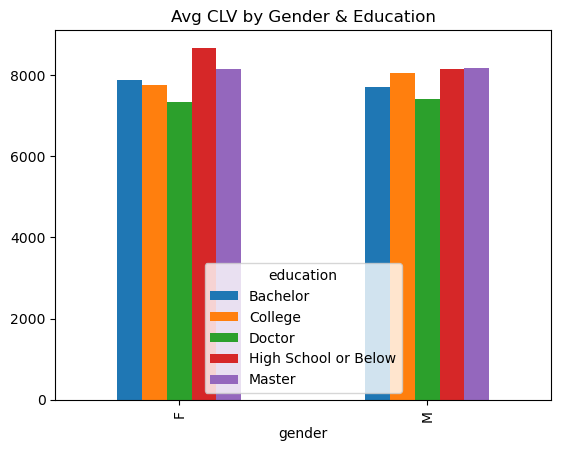

In [13]:
pivot_clv.plot.bar(title="Avg CLV by Gender & Education")


1. You work at the marketing department and you want to know which sales channel brought the most sales in terms of total revenue. Using pivot, create a summary table showing the total revenue for each sales channel (branch, call center, web, and mail).
Round the total revenue to 2 decimal points.  Analyze the resulting table to draw insights.

2. Create a pivot table that shows the average customer lifetime value per gender and education level. Analyze the resulting table to draw insights.

## Bonus

You work at the customer service department and you want to know which months had the highest number of complaints by policy type category. Create a summary table showing the number of complaints by policy type and month.
Show it in a long format table.

*In data analysis, a long format table is a way of structuring data in which each observation or measurement is stored in a separate row of the table. The key characteristic of a long format table is that each column represents a single variable, and each row represents a single observation of that variable.*

*More information about long and wide format tables here: https://www.statology.org/long-vs-wide-data/*

In [ ]:
# Your code goes here